# 20nodes_EB_obsconf0_latconf0_NonGaussian_Linear: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf0_latconf0_NonGaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.482147,0.094122,15
1,DAGMA_Linear,0.179834,0.062507,15
2,DAGMA_Nonlinear,0.127936,0.065787,15
3,DAS,0.132329,0.078659,15
4,DirectLiNGAM,0.998338,0.003452,15
5,FCI,0.079064,0.064368,15
6,GES,0.444371,0.152219,15
7,GOLEM,0.150278,0.090959,15
8,GRaSP,0.755768,0.114259,15
9,GraNDAG,0.055841,0.045595,15


,model,mean,std,size
0,AVICI,53.133333,10.802557,15
1,DAGMA_Linear,61.533333,7.558029,15
2,DAGMA_Nonlinear,70.022222,10.394616,15
3,DAS,100.866667,16.012793,15
4,DirectLiNGAM,0.200000,0.414039,15
5,FCI,62.591111,7.203388,15
6,GES,80.266667,27.112113,15
7,GOLEM,84.400000,13.473784,15
8,GRaSP,28.404444,15.397598,15
9,GraNDAG,57.000000,6.425396,15


,model,mean,std,size
0,AVICI,0.520888,0.086642,15
1,DAGMA_Linear,0.254303,0.093185,15
2,DAGMA_Nonlinear,0.168495,0.097562,15
3,DAS,0.108627,0.068075,15
4,DirectLiNGAM,0.996703,0.006847,15
5,FCI,0.474286,0.325010,15
6,GES,0.351642,0.155224,15
7,GOLEM,0.140473,0.084687,15
8,GRaSP,0.742714,0.136278,15
9,GraNDAG,0.327340,0.240293,15


,model,mean,std,size
0,AVICI,0.458163,0.115946,15
1,DAGMA_Linear,0.140966,0.050466,15
2,DAGMA_Nonlinear,0.107426,0.053205,15
3,DAS,0.171941,0.096568,15
4,DirectLiNGAM,1.000000,0.000000,15
5,FCI,0.044149,0.037910,15
6,GES,0.620301,0.137388,15
7,GOLEM,0.162620,0.099699,15
8,GRaSP,0.781451,0.092455,15
9,GraNDAG,0.031899,0.027870,15


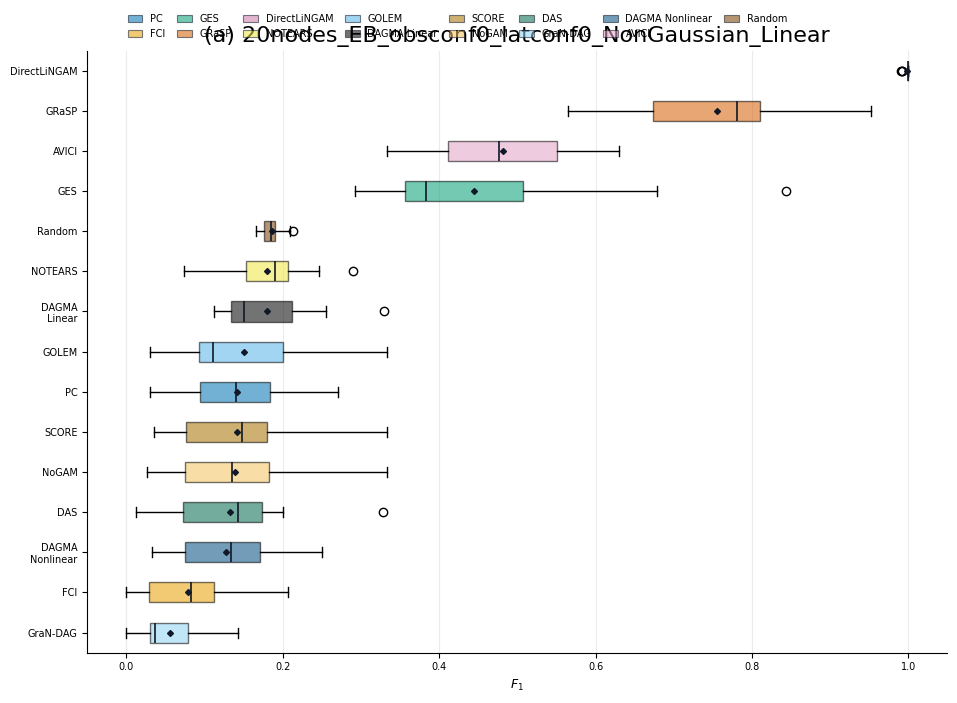

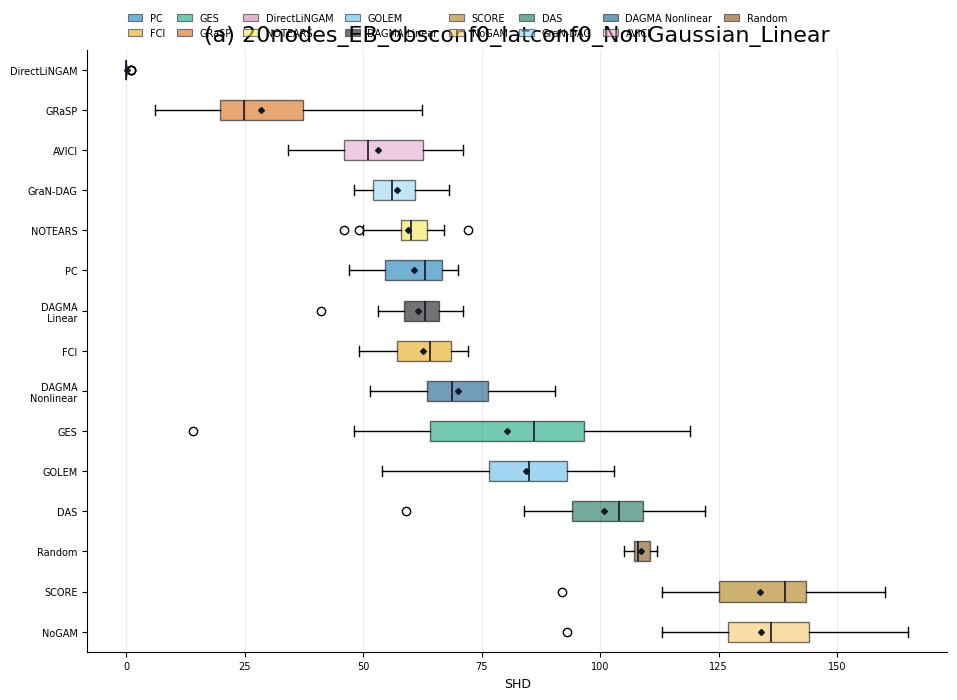

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.168217
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.712608
9,13,GraNDAG,0.000000


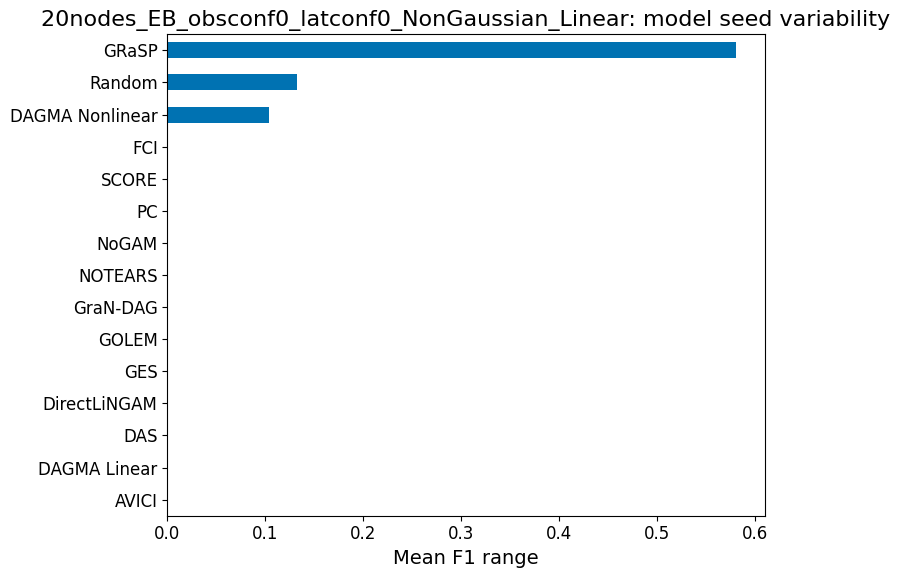

,model_seed,model,f1_range
0,0,AVICI,0.297297
1,0,DAGMA_Linear,0.216754
2,0,DAGMA_Nonlinear,0.282593
3,0,DAS,0.315681
4,0,DirectLiNGAM,0.009009
5,0,FCI,0.206897
6,0,GES,0.550208
7,0,GOLEM,0.302799
8,0,GRaSP,0.743590
9,0,GraNDAG,0.142857


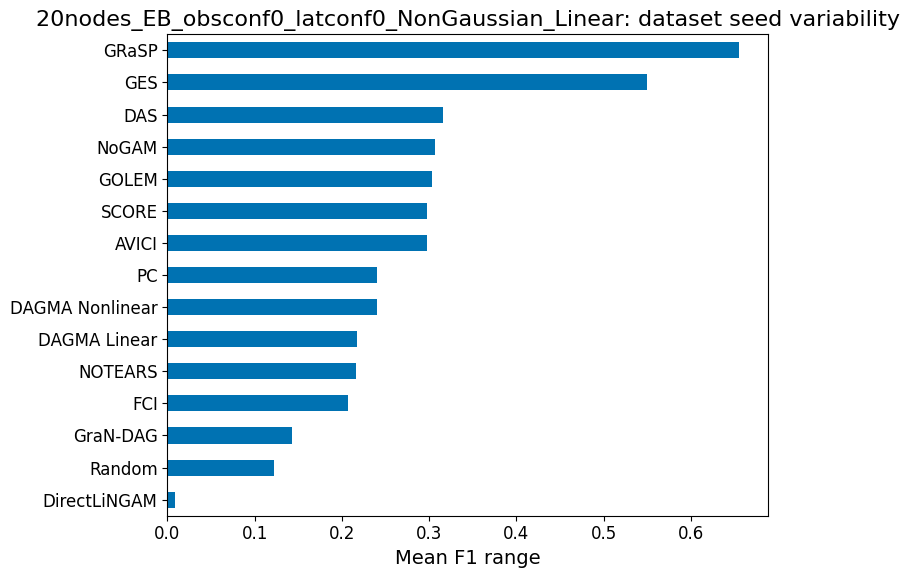

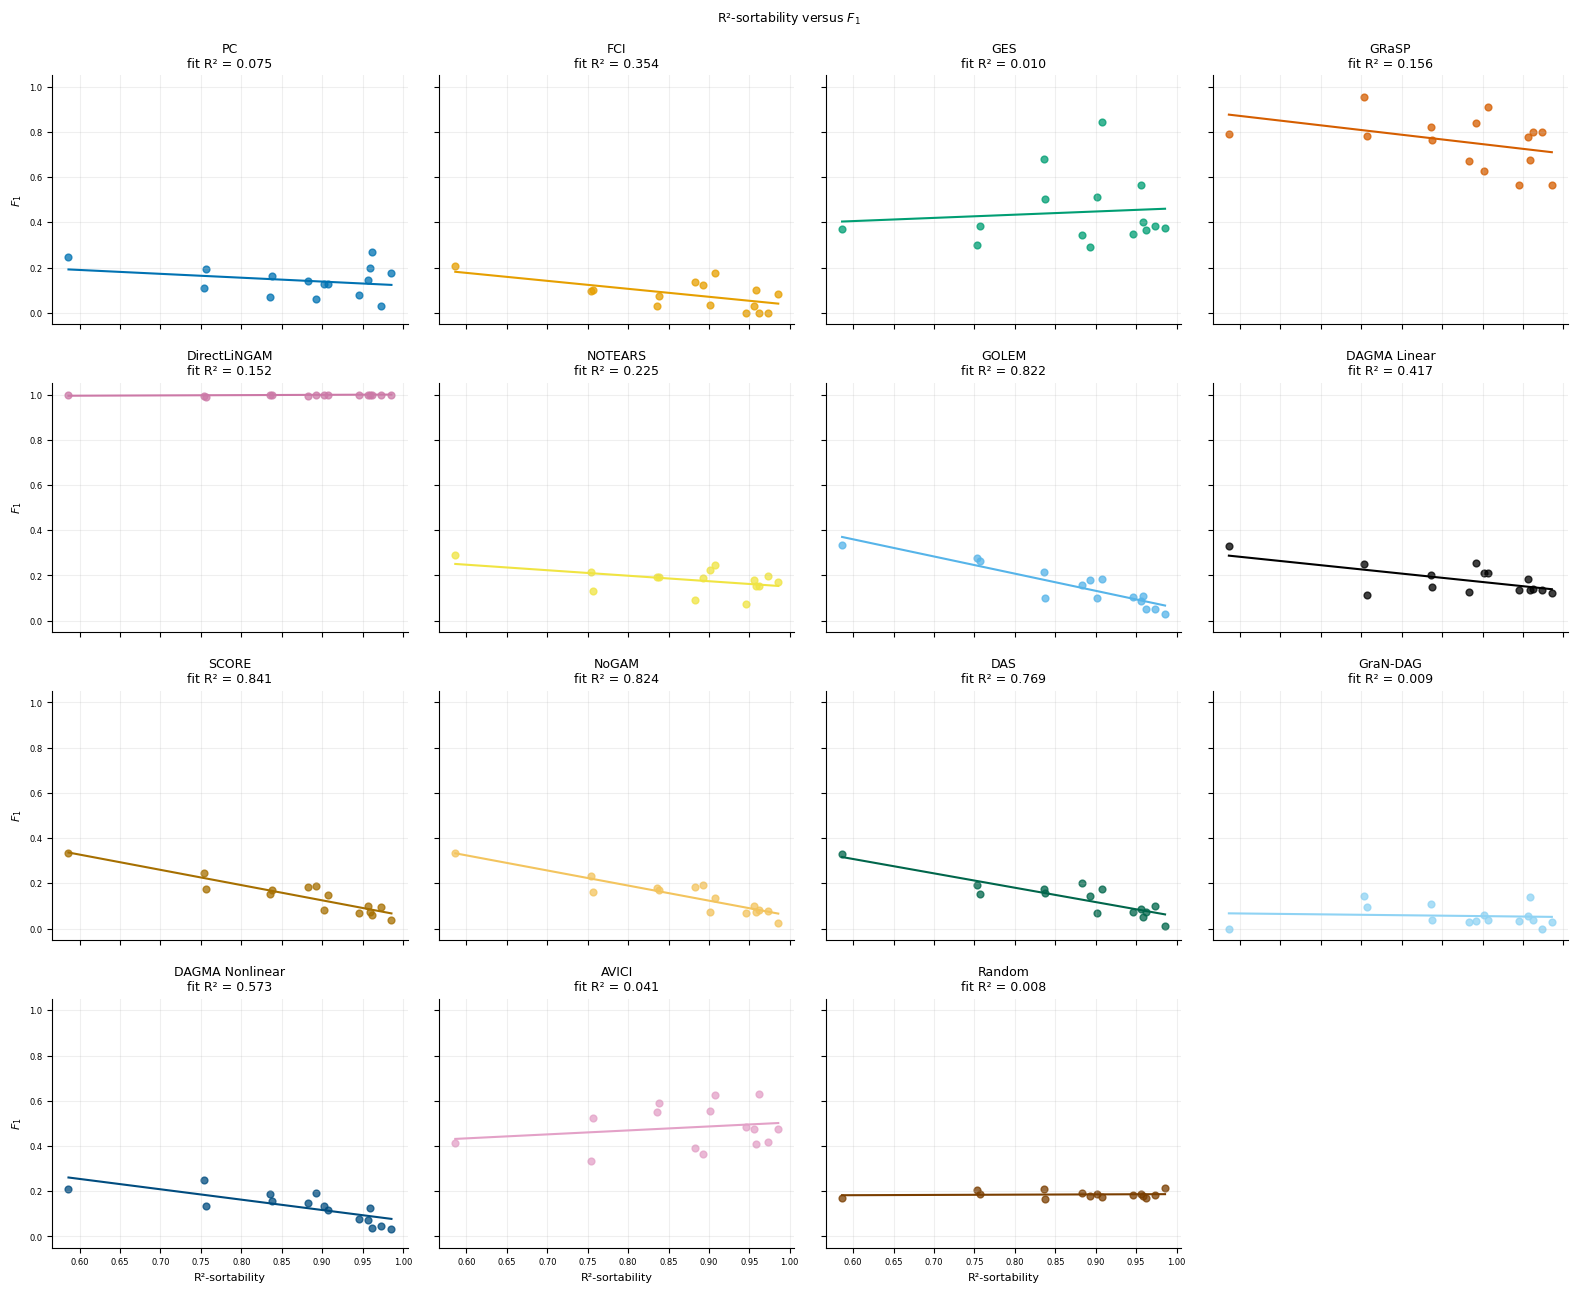

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,0.590476,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,0.150538,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,0.154575,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,0.158273,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,1.000000,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,0.075472,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,0.503597,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,0.100000,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,0.763924,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,0.037037,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.996139,0.972973,259,258,0,252,0,20,2000
1,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
2,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.910345,0.586207,145,132,0,85,0,20,2000
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963731,0.756477,193,186,0,146,0,20,2000
4,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.954717,0.901887,265,253,0,239,0,20,2000
5,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.965854,0.907317,205,198,0,186,0,20,2000
6,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.978125,0.956250,320,313,0,306,0,20,2000
7,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.969274,0.882682,358,347,0,316,0,20,2000
8,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.987864,0.958738,412,407,0,395,0,20,2000
9,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.988124,0.985748,421,416,0,415,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.202798,0.041127,0.175671,0.328308,0.468526,0.192857,0.491049
1,DAGMA_Linear,15,-0.645899,0.417185,-0.371567,0.505223,0.009291,-0.437891,0.102576
2,DAGMA_Nonlinear,15,-0.756844,0.572813,-0.458239,0.529225,0.001089,-0.896429,0.000006
3,DAS,15,-0.877030,0.769181,-0.634902,0.688325,0.000018,-0.778571,0.000627
4,DirectLiNGAM,15,0.389880,0.152006,0.012388,0.987489,0.150834,0.513129,0.050444
5,FCI,15,-0.594920,0.353930,-0.352433,0.387696,0.019314,-0.478929,0.070890
6,GES,15,0.101058,0.010213,0.141575,0.320390,0.720073,0.103571,0.713380
7,GOLEM,15,-0.906812,0.822308,-0.759113,0.815049,0.000003,-0.871429,0.000023
8,GRaSP,15,-0.395482,0.156406,-0.415876,1.119959,0.144541,-0.335714,0.221212
9,GraNDAG,15,-0.092852,0.008621,-0.038963,0.089962,0.742059,-0.262970,0.343672


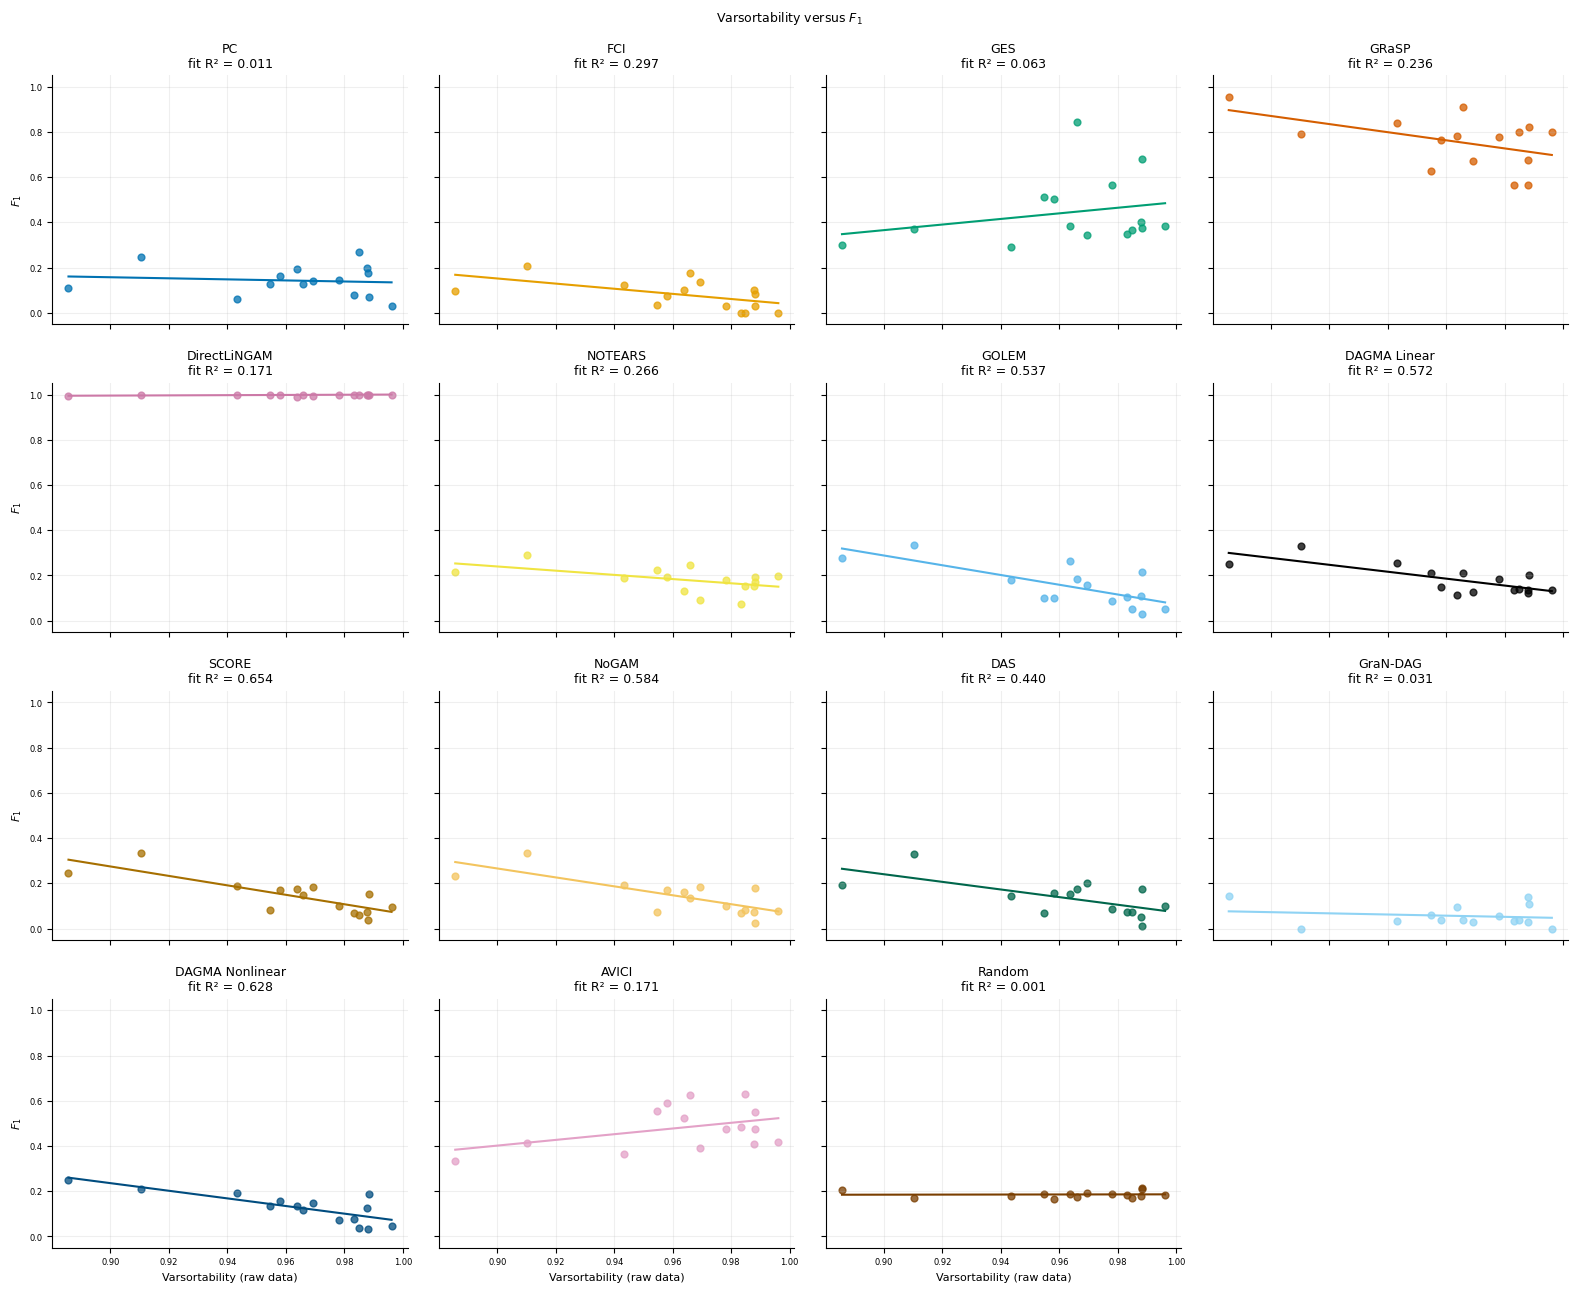

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,0.590476,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,0.150538,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,0.154575,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,0.158273,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,1.000000,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,0.075472,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,0.503597,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,0.100000,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,0.763924,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,0.037037,15,20,EB,0,0,NonGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.996139,0.972973,259,258,0,252,0,20,2000
1,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958115,0.837696,191,183,0,160,0,20,2000
2,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.910345,0.586207,145,132,0,85,0,20,2000
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963731,0.756477,193,186,0,146,0,20,2000
4,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.954717,0.901887,265,253,0,239,0,20,2000
5,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.965854,0.907317,205,198,0,186,0,20,2000
6,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.978125,0.956250,320,313,0,306,0,20,2000
7,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.969274,0.882682,358,347,0,316,0,20,2000
8,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.987864,0.958738,412,407,0,395,0,20,2000
9,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.988124,0.985748,421,416,0,415,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.414098,0.171477,1.260719,-0.732994,0.124904,0.235714,0.397703
1,DAGMA_Linear,15,-0.756511,0.572309,-1.529559,1.654096,0.001098,-0.595175,0.019249
2,DAGMA_Nonlinear,15,-0.792443,0.627966,-1.686291,1.753262,0.000427,-0.710714,0.002979
3,DAS,15,-0.663060,0.439649,-1.687033,1.758371,0.007053,-0.485714,0.066426
4,DirectLiNGAM,15,0.413265,0.170788,0.046151,0.953855,0.125740,0.354851,0.194345
5,FCI,15,-0.545066,0.297097,-1.134866,1.172902,0.035617,-0.566822,0.027573
6,GES,15,0.251395,0.063199,1.237798,-0.748678,0.366092,0.292857,0.289472
7,GOLEM,15,-0.733024,0.537324,-2.156678,2.228987,0.001877,-0.567857,0.027228
8,GRaSP,15,-0.485582,0.235790,-1.794643,2.485529,0.066511,-0.250000,0.368846
9,GraNDAG,15,-0.175010,0.030628,-0.258112,0.304621,0.532724,-0.123435,0.661190


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_NonGaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,r2_sortability,15,0.192857,0.491049,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.437891,0.102576,estimated,0.820607
2,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.896429,0.000006,estimated,0.000091
3,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,r2_sortability,15,-0.778571,0.000627,estimated,0.006901
4,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,r2_sortability,15,0.513129,0.050444,estimated,0.504444
5,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,r2_sortability,15,-0.478929,0.070890,estimated,0.638010
6,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,r2_sortability,15,0.103571,0.713380,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,r2_sortability,15,-0.871429,0.000023,estimated,0.000325
8,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,r2_sortability,15,-0.335714,0.221212,estimated,1.000000
9,benchmark,untuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,r2_sortability,15,-0.262970,0.343672,estimated,1.000000
